# Đồ án Cuối kỳ AI & Machine Learning: Dự đoán Giá Nhà tại Việt Nam (2024)

**Bài toán:** Hồi quy liên tục (`Price`, đơn vị **tỷ VND**) trên bộ dữ liệu **Vietnam Housing Dataset 2024** (`30,229` tin đăng, `12` cột).  
**Giảng viên hướng dẫn:** PhD. Truc Thi Kim, Nguyen  

---

## Kiến trúc Thực nghiệm & Nội dung Notebook

Notebook này tổng hợp toàn bộ quy trình dữ liệu, thực nghiệm kiểm chứng mô hình, đánh giá trên tập Test độc lập và diễn giải kết quả theo đúng cấu trúc báo cáo:

1. **Khám phá Dữ liệu (EDA — 20%):** Phân bố giá bán/đơn giá, mức độ thiếu dữ liệu (40–83%), lỗi Unicode tiếng Việt và nhóm tin đăng trùng lặp môi giới.
2. **Tiền xử lý & Feature Engineering (`P0 → P4`):** Kiểm chứng trực tiếp các bộ đặc trưng không rò rỉ dữ liệu (`Group-Stratified Split 70/15/15`, OOF `Price/m²` priors, OOF TF-IDF Ridge).
3. **Huấn luyện & Tối ưu Hai Hướng Mô hình Chính (30%):**
   - **Hướng 1:** *Linear Regression (Mini-batch SGD)* (`L01–L05`) làm mốc chuẩn tuyến tính dựa trên gradient MSE.
   - **Hướng 2:** *MLP (Backpropagation + Adam)* (`N01–N06` + kiểm tra đa seed `42, 123, 2026`) trên Google Colab T4 GPU.
   - **Tham chiếu bên ngoài:** *HistGradientBoostingRegressor (`HGB`)* & *Random Forest (`RF`)* trên `P4_geo_priors`.
4. **Đánh giá Tập Test Độc lập & Phân tích Sai số (20%):** Chỉ số `RMSE`, `MAE`, `MedAE`, `R²`, `MAPE`, độ chính xác dung sai `±10% / ±20% / ±1 tỷ`, phân tích theo phân khúc giá & vùng miền, và *Permutation Importance*.
5. **Tổng kết & Liên hệ Kiến thức Môn học (20%):** Bias–Variance Trade-off, SGD vs. Adam, vai trò áp đảo của Feature Engineering và kỷ luật chống *Data Leakage*.

In [41]:
import csv
import json
import sys
from pathlib import Path

import matplotlib
import numpy as np
import sklearn

PROJECT_ROOT = Path("/Users/isoamyl50/machine-learning/final-project")
assert PROJECT_ROOT.is_dir(), f"Missing PROJECT_ROOT: {PROJECT_ROOT}"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import ARTIFACTS_DIR, DATA_RAW_PATH, EXPERIMENTS_RUNS_DIR, EXPERIMENTS_SPLITS_PATH, SLIDES_FIGURES_DIR
from src.evaluate import evaluate_predictions
from src.features import build_feature_recipe
from src.preprocessing import normalize_vietnamese_text, parse_address
from src.splits import build_repost_group_key, load_frozen_splits, load_raw_records

print(f"Python       : {sys.version.split()[0]} ({sys.executable})")
print(f"NumPy        : {np.__version__} | scikit-learn: {sklearn.__version__} | Matplotlib: {matplotlib.__version__}")
print(f"Dataset CSV  : {DATA_RAW_PATH.name} ({DATA_RAW_PATH.stat().st_size:,} bytes)")

rows = load_raw_records()
tr_idx, va_idx, te_idx = load_frozen_splits(path=EXPERIMENTS_SPLITS_PATH, rows=rows)

# Verify zero row overlap and zero repost-group overlap across splits
tr_set, va_set, te_set = set(tr_idx.tolist()), set(va_idx.tolist()), set(te_idx.tolist())
assert len(tr_set & va_set) == 0 and len(tr_set & te_set) == 0 and len(va_set & te_set) == 0

groups = [build_repost_group_key(r) for r in rows]
g_tr = {groups[i] for i in tr_idx}
g_va = {groups[i] for i in va_idx}
g_te = {groups[i] for i in te_idx}
assert len(g_tr & g_va) == 0 and len(g_tr & g_te) == 0 and len(g_va & g_te) == 0

print(f"Total rows   : {len(rows):,} | Unique repost groups: {len(set(groups)):,}")
print(f"Frozen split : Train={len(tr_idx):,} ({len(tr_idx)/len(rows):.1%}), Val={len(va_idx):,} ({len(va_idx)/len(rows):.1%}), Test={len(te_idx):,} ({len(te_idx)/len(rows):.1%})")
print("Integrity OK : 0 row overlap & 0 repost-group leakage across Train/Val/Test.")

Python       : 3.12.16 (/Users/isoamyl50/machine-learning/.venv/bin/python)
NumPy        : 2.5.5 | scikit-learn: 1.9.1 | Matplotlib: 3.11.2
Dataset CSV  : vietnam_housing_dataset.csv (3,532,685 bytes)
Total rows   : 30,229 | Unique repost groups: 27,748
Frozen split : Train=21,161 (70.0%), Val=4,535 (15.0%), Test=4,533 (15.0%)
Integrity OK : 0 row overlap & 0 repost-group leakage across Train/Val/Test.


## Phần 1 — Khám phá Dữ liệu (Exploratory Data Analysis — 20%)

Bộ dữ liệu gồm **30,229 tin đăng bất động sản (12 cột)** tại Việt Nam. Khám phá sơ bộ cho thấy 3 vấn đề trọng yếu cần xử lý trước khi huấn luyện:
- **Thiếu dữ liệu nặng ở nhiều cột thuộc tính:** `Balcony direction` thiếu **82.65%**, `House direction` **70.26%**, `Furniture state` **46.71%**, `Access Road` **43.99%**, `Frontage` **38.25%**. Việc loại bỏ dòng thiếu (`dropna`) sẽ làm mất **91.25%** dữ liệu.
- **Chuỗi tiếng Việt không đồng nhất:** Tổ hợp dấu Unicode NFD/NFC (`Hà Nội` vs. `Hà Nội`) và tên viết tắt (`TP. HCM` vs. `Hồ Chí Minh`), cùng địa chỉ ngắn sai chuẩn.
- **Tin đăng lặp của môi giới:** **1,708 cụm tin đăng lặp** (`4,189` dòng) cùng khóa `Address | Area | Floors | Bedrooms | Bathrooms` cần tách theo nhóm để chống *data leakage*.

In [42]:
from collections import Counter

field_names = list(rows[0].keys())
print(f"Dataset shape: {len(rows):,} rows x {len(field_names)} columns -> {field_names}")

# Exact missingness rate per column
print("\nMissingness summary:")
complete_rows = 0
for r in rows:
    if all(str(r.get(c, "")).strip() != "" for c in field_names):
        complete_rows += 1

for col in field_names:
    n_miss = sum(1 for r in rows if str(r.get(col, "")).strip() == "")
    if n_miss > 0:
        print(f"  {col:18s}: {n_miss:6,d} ({100.0 * n_miss / len(rows):5.2f}%)")
print(f"Complete rows (dropna keeps): {complete_rows:,} / {len(rows):,} ({100.0 * complete_rows / len(rows):.2f}%)")

# Target statistics
prices = np.array([float(r["Price"]) for r in rows], dtype=float)
areas = np.array([float(r["Area"]) for r in rows], dtype=float)
ppm2 = (prices * 1000.0) / np.maximum(areas, 1.0)
print(
    f"\nPrice (billion VND): min={prices.min():.2f}, q25={np.quantile(prices, 0.25):.2f}, "
    f"median={np.median(prices):.2f}, mean={prices.mean():.3f}, q75={np.quantile(prices, 0.75):.2f}, "
    f"max={prices.max():.2f}, std={prices.std():.3f}"
)
print(f"Price/m² (triệu/m²): median={np.median(ppm2):.2f}, mean={ppm2.mean():.2f}, p95={np.quantile(ppm2, 0.95):.2f}")

# Unicode & repost anomalies
raw_last_tokens = Counter(str(r.get("Address", "")).split(",")[-1].strip().rstrip(".") for r in rows)
nfd_hn = sum(cnt for tok, cnt in raw_last_tokens.items() if "nô" in tok.lower() or ("hà nội" not in tok.lower() and normalize_vietnamese_text(tok) == "Hà Nội"))
tphcm_alias = raw_last_tokens.get("TP HCM", 0) + raw_last_tokens.get("TP. HCM", 0)
clean_cities = Counter(parse_address(r.get("Address"))["city"] for r in rows)
rep_counts = Counter(groups)
n_multi_groups = sum(1 for k, c in rep_counts.items() if c > 1)
n_multi_rows = sum(c for k, c in rep_counts.items() if c > 1)
print(f"\nUnicode NFD Hanoi variants fixed: {nfd_hn} rows | TP.HCM alias variants fixed: {tphcm_alias} rows")
print(f"Repost duplicate clusters (>1 row): {n_multi_groups:,} groups covering {n_multi_rows:,} listings")
print("Top 6 cities after NFC normalization:", clean_cities.most_common(6))

Dataset shape: 30,229 rows x 12 columns -> ['Address', 'Area', 'Frontage', 'Access Road', 'House direction', 'Balcony direction', 'Floors', 'Bedrooms', 'Bathrooms', 'Legal status', 'Furniture state', 'Price']

Missingness summary:
  Frontage          : 11,564 (38.25%)
  Access Road       : 13,297 (43.99%)
  House direction   : 21,239 (70.26%)
  Balcony direction : 24,983 (82.65%)
  Floors            :  3,603 (11.92%)
  Bedrooms          :  5,162 (17.08%)
  Bathrooms         :  7,074 (23.40%)
  Legal status      :  4,506 (14.91%)
  Furniture state   : 14,119 (46.71%)
Complete rows (dropna keeps): 2,645 / 30,229 (8.75%)

Price (billion VND): min=1.00, q25=4.20, median=5.90, mean=5.872, q75=7.50, max=11.50, std=2.212
Price/m² (triệu/m²): median=102.27, mean=107.91, p95=205.50



Unicode NFD Hanoi variants fixed: 4 rows | TP.HCM alias variants fixed: 2 rows
Repost duplicate clusters (>1 row): 1,708 groups covering 4,189 listings
Top 6 cities after NFC normalization: [('Hồ Chí Minh', 11780), ('Hà Nội', 10462), ('Bình Dương', 1672), ('Đà Nẵng', 1437), ('Đồng Nai', 829), ('Hải Phòng', 789)]


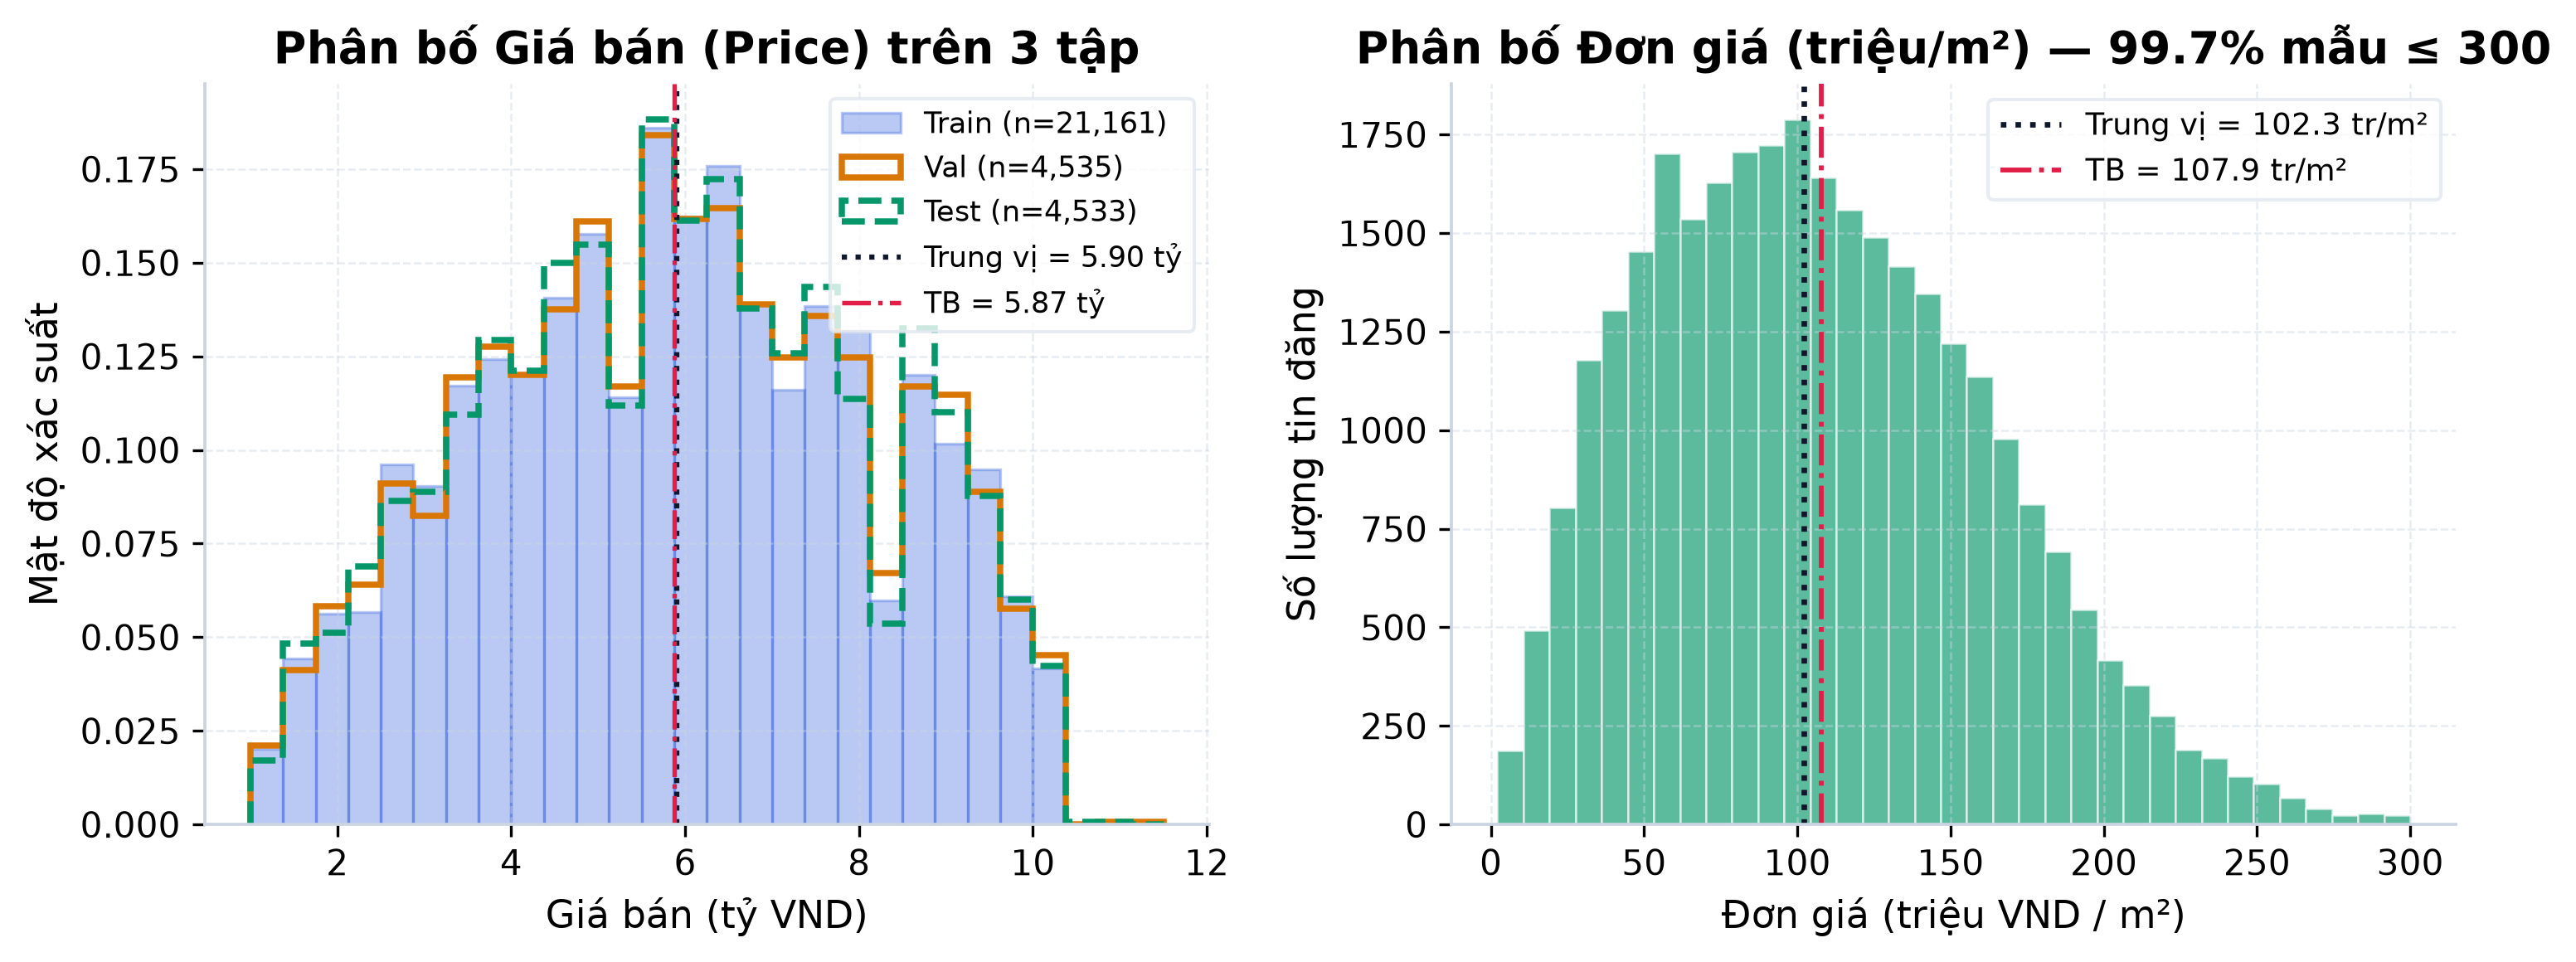

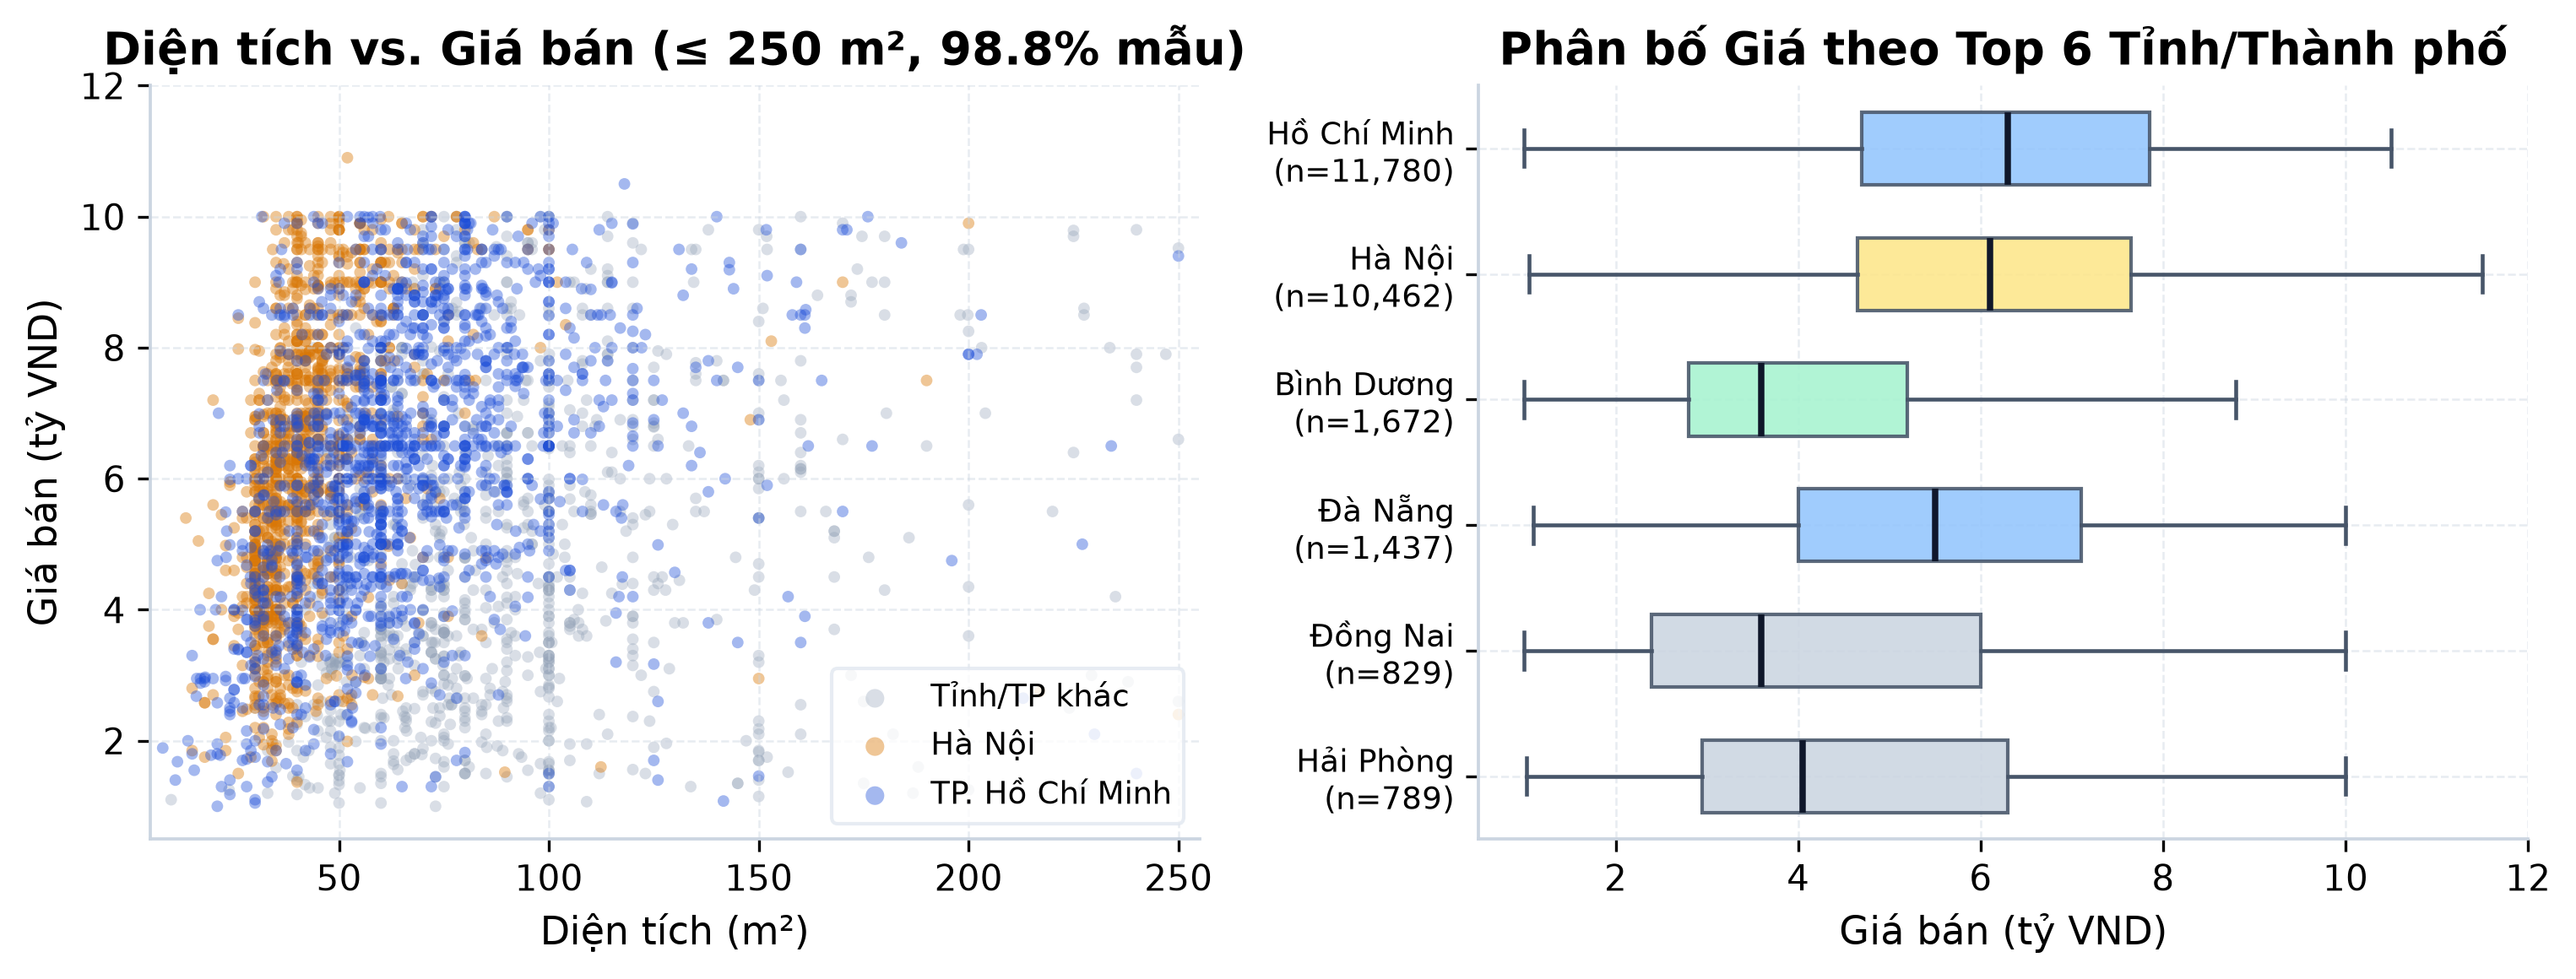

In [43]:
from IPython.display import Image, display

for fig_name in ("price_distribution.png", "dataset_samples.png"):
    p = SLIDES_FIGURES_DIR / fig_name
    assert p.is_file(), f"Missing figure: {p}"
    display(Image(filename=str(p), width=820))

## Phần 2 — Tiền xử lý & Kỹ thuật Tạo Đặc trưng (`P0 → P4`)

Pipeline tiền xử lý trong [`src/features.py`](../src/features.py) được thiết kế **nghiêm ngặt chỉ fit trên tập Train** (`21,161` mẫu):
1. **Chuẩn hóa địa chỉ & Imputation theo Quận/Huyện:** Chuẩn hóa Unicode NFC, hợp nhất alias tỉnh/thành phố, trích xuất phân cấp `City → District → Ward → Street`, cờ nhận diện nhà mặt tiền/dự án/hẻm (`is_project`, `is_alley`) và điền khuyết trung vị theo quận + biến cờ báo thiếu.
2. **Đặc trưng cấu trúc phi tuyến:** `log1p(Area)`, `usable_area = Area × Floors`, `Area/Floor`, `Total_Rooms`, `Area/Bedroom`, `Frontage/AccessRoad`.
3. **5-fold Out-of-Fold (OOF) Geo Priors & TF-IDF Ridge (`P4_geo_priors`):** Tính smoothed `Price` và `Price/m²` theo 4 cấp địa lý kết hợp `Ridge TF-IDF` trên chuỗi địa chỉ hoàn toàn theo cơ chế OOF trên Train để không rò rỉ nhãn mục tiêu.
4. **Chuẩn hóa có chọn lọc (`StandardScaler`):** Chỉ scale các khối đặc trưng liên tục; các cột nhị phân `0/1` (biến cờ thiếu & One-Hot Encoding) được giữ nguyên miền `[0, 1]`.

In [44]:
# Live verification of Feature Engineering recipes (P0 -> P2 -> P4_compact -> P4_geo_priors)
tr_rows = [rows[i] for i in tr_idx]
va_rows = [rows[i] for i in va_idx]
te_rows = [rows[i] for i in te_idx]
y_tr_price = np.array([float(r["Price"]) for r in tr_rows], dtype=float)

# Verify address normalization & parsing
sample_addr = "Đường 3/2, Phường 11, Quận 10, TP. HCM"
print("Sample parsed address:", parse_address(sample_addr))
print("NFD -> NFC normalization:", normalize_vietnamese_text("Ha\u0300 Nô\u0323i") == "Hà Nội")

print("\nFeature recipe matrix verification (scaled=True, preserve_nans=False):")
for feat_name in ("P0_numeric", "P2_domain", "P4_compact", "P4_geo_priors"):
    rec = build_feature_recipe(feat_name, scale_numeric=True, preserve_nans=False)
    X_tr = rec.fit_transform(tr_rows, y_train_price=y_tr_price)
    X_va = rec.transform(va_rows)
    X_te = rec.transform(te_rows)

    assert np.isnan(X_tr).sum() == 0 and np.isnan(X_va).sum() == 0 and np.isnan(X_te).sum() == 0
    assert np.isinf(X_tr).sum() == 0 and np.isinf(X_va).sum() == 0 and np.isinf(X_te).sum() == 0

    ohe_cols = [
        i for i, c in enumerate(rec.feature_names)
        if any(c.startswith(p) for p in ("city_", "district_", "ward_", "Legal ", "Furniture ", "House "))
    ]
    ohe_max = float(np.max(np.abs(X_tr[:, ohe_cols]))) if ohe_cols else 0.0
    print(
        f"  {feat_name:14s}: Train={X_tr.shape}, Val={X_va.shape}, Test={X_te.shape} | "
        f"NaN=0, Inf=0 | OHE cols={len(ohe_cols):3d} (max={ohe_max:.1f})"
    )

Sample parsed address: {'city': 'Hồ Chí Minh', 'district': 'Quận 10 | Hồ Chí Minh', 'ward': 'Phường 11', 'is_project': 0, 'is_alley': 0}
NFD -> NFC normalization: True

Feature recipe matrix verification (scaled=True, preserve_nans=False):
  P0_numeric    : Train=(21161, 6), Val=(4535, 6), Test=(4533, 6) | NaN=0, Inf=0 | OHE cols=  0 (max=0.0)


  P2_domain     : Train=(21161, 306), Val=(4535, 306), Test=(4533, 306) | NaN=0, Inf=0 | OHE cols=283 (max=1.0)


  P4_compact    : Train=(21161, 103), Val=(4535, 103), Test=(4533, 103) | NaN=0, Inf=0 | OHE cols= 41 (max=1.0)


  P4_geo_priors : Train=(21161, 345), Val=(4535, 345), Test=(4533, 345) | NaN=0, Inf=0 | OHE cols=283 (max=1.0)


## Phần 3 — Lựa chọn Mô hình & Thí nghiệm Validation Có kiểm soát (30%)

Nhóm triển khai hai họ mô hình gradient-based từ kiến thức môn học trong [`src/models.py`](../src/models.py) và chạy thực nghiệm có kiểm soát trên **Google Colab Tesla T4 GPU** ([`scripts/run_colab_overnight.py`](../scripts/run_colab_overnight.py)):

1. **Hướng 1 — Linear Regression (`Mini-batch SGD`, `linear_sgd`):**
   $$\hat{y} = \mathbf{w}^\top \mathbf{x} + b, \qquad \mathcal{L}_{\text{MSE}} = \frac{1}{B}\sum_{i=1}^B (\hat{y}_i - y_i)^2$$
   Thử nghiệm tuần tự `L01–L05` (batch size `128 / 256 / 512`, learning rate `0.001 / 0.003 / 0.01 / 0.05`, weight decay `1e-4`), `grad_clip=5.0`, Early Stopping (`patience=20`).
2. **Hướng 2 — Multi-Layer Perceptron (`Backpropagation + Adam`, `mlp`):**
   $$\mathbf{h} = \text{ReLU}(W_1 \mathbf{x} + \mathbf{b}_1), \qquad \hat{y} = \mathbf{w}_2^\top \mathbf{h} + b_2$$
   Khảo sát tuần tự `N01–N06` (số neuron `(32,), (64,), (128,)`, mạng 2 tầng `(128, 64)` ± `BatchNorm1d`, batch size, learning rate `1e-3 / 3e-4`, `Dropout(0.1 / 0.2)`, hàm mất mát `MSE / Huber / SmoothL1`, `L2 weight_decay=1e-4`, biến đổi mục tiêu `log1p(Price)`) và **kiểm chứng đa seed (`42, 123, 2026`)**.
3. **Tham chiếu bên ngoài:** `HistGradientBoostingRegressor (HGB)` & `RandomForestRegressor (RF)` trên cùng split và `P4_geo_priors`.

In [45]:
summary = json.loads((ARTIFACTS_DIR / "final_summary.json").read_text(encoding="utf-8"))
all_runs = [json.loads(p.read_text(encoding="utf-8")) for p in sorted(EXPERIMENTS_RUNS_DIR.glob("*.json"))]
print(f"Loaded {len(all_runs)} logged experiment JSONs from experiments/runs/ (GPU: {summary['environment']['gpu']})")

print("\n=== 1. Preprocessing Ablation (Val RMSE / R², seed=42) ===")
for feat in ("P0_numeric", "P2_domain", "P4_compact", "P4_geo_priors"):
    l_m = summary["ablation"]["linear_sgd"][feat]["val"]
    m_m = summary["ablation"]["mlp"][feat]["val"]
    h_m = summary["ablation"]["hgb"][feat]["val"]
    print(
        f"  {feat:14s} | Linear SGD: {l_m['rmse']:.4f} (R2={l_m['r2']:.4f}) | "
        f"MLP Adam: {m_m['rmse']:.4f} (R2={m_m['r2']:.4f}) | HGB Ref: {h_m['rmse']:.4f} (R2={h_m['r2']:.4f})"
    )

print("\n=== 2. Track 1 — Linear Regression + Mini-batch SGD (L01–L05 on P4_geo_priors) ===")
for r in summary["track1_linear_sgd"]:
    p, v, h = r["params"], r["val"], r["history_meta"]
    print(
        f"  {r['tag']:5s} | bs={p['batch_size']:3d} lr={p['lr']:<6g} wd={p['weight_decay']:<6g} | "
        f"Val RMSE={v['rmse']:.4f} MAE={v['mae']:.4f} R2={v['r2']:.4f} ±10%={v['within_10pct']:.4f} | "
        f"ep={h['best_epoch']:3d}/{h['stopped_epoch']:3d}"
    )

print("\n=== 3. Track 2 — MLP + Backpropagation + Adam (N01–N06 on P4_geo_priors) ===")
for r in summary["track2_mlp"]:
    p, v, h = r["params"], r["val"], r["history_meta"]
    print(
        f"  {r['tag']:5s} | tgt={r['target']:5s} arch={str(p['hidden_dims']):9s} bn={str(p['use_batchnorm']):5s} "
        f"bs={p['batch_size']:3d} lr={p['lr']:<6g} drop={p['dropout']:.1f} loss={p['loss']:9s} wd={p['weight_decay']:<6g} | "
        f"RMSE={v['rmse']:.4f} MAE={v['mae']:.4f} R2={v['r2']:.4f} ±10%={v['within_10pct']:.4f} ep={h['best_epoch']:2d}/{h['stopped_epoch']:2d}"
    )

ms = summary["multiseed_mlp"]
print("\n=== 4. Multi-Seed MLP Stability Verification (42, 123, 2026) ===")
for r in ms["runs"]:
    v = r["val"]
    print(f"  seed={r['seed']:4d} -> Val RMSE={v['rmse']:.4f} | MAE={v['mae']:.4f} | R2={v['r2']:.4f} | ±10%={v['within_10pct']:.4f}")
print(
    f"  Summary   -> Val RMSE = {ms['rmse']['mean']:.4f} ± {ms['rmse']['std']:.4f} | "
    f"R2 = {ms['r2']['mean']:.4f} ± {ms['r2']['std']:.4f} | ±20% = {ms['within_20pct']['mean']:.4f} ± {ms['within_20pct']['std']:.4f}"
)

Loaded 41 logged experiment JSONs from experiments/runs/ (GPU: Tesla T4)

=== 1. Preprocessing Ablation (Val RMSE / R², seed=42) ===
  P0_numeric     | Linear SGD: 1.9956 (R2=0.1897) | MLP Adam: 1.8541 (R2=0.3006) | HGB Ref: 1.7924 (R2=0.3464)
  P2_domain      | Linear SGD: 1.4210 (R2=0.5891) | MLP Adam: 1.3151 (R2=0.6481) | HGB Ref: 1.3027 (R2=0.6547)
  P4_compact     | Linear SGD: 1.2931 (R2=0.6598) | MLP Adam: 1.2173 (R2=0.6985) | HGB Ref: 1.1711 (R2=0.7210)
  P4_geo_priors  | Linear SGD: 1.2830 (R2=0.6651) | MLP Adam: 1.2123 (R2=0.7010) | HGB Ref: 1.1747 (R2=0.7192)

=== 2. Track 1 — Linear Regression + Mini-batch SGD (L01–L05 on P4_geo_priors) ===
  L01   | bs=256 lr=0.01   wd=0      | Val RMSE=1.2830 MAE=0.9626 R2=0.6651 ±10%=0.3916 | ep= 83/103
  L02   | bs=128 lr=0.01   wd=0      | Val RMSE=1.2816 MAE=0.9600 R2=0.6658 ±10%=0.3971 | ep= 72/ 92
  L03   | bs=512 lr=0.01   wd=0      | Val RMSE=1.2847 MAE=0.9644 R2=0.6642 ±10%=0.3907 | ep=120/140
  L04a  | bs=256 lr=0.001  wd=0     

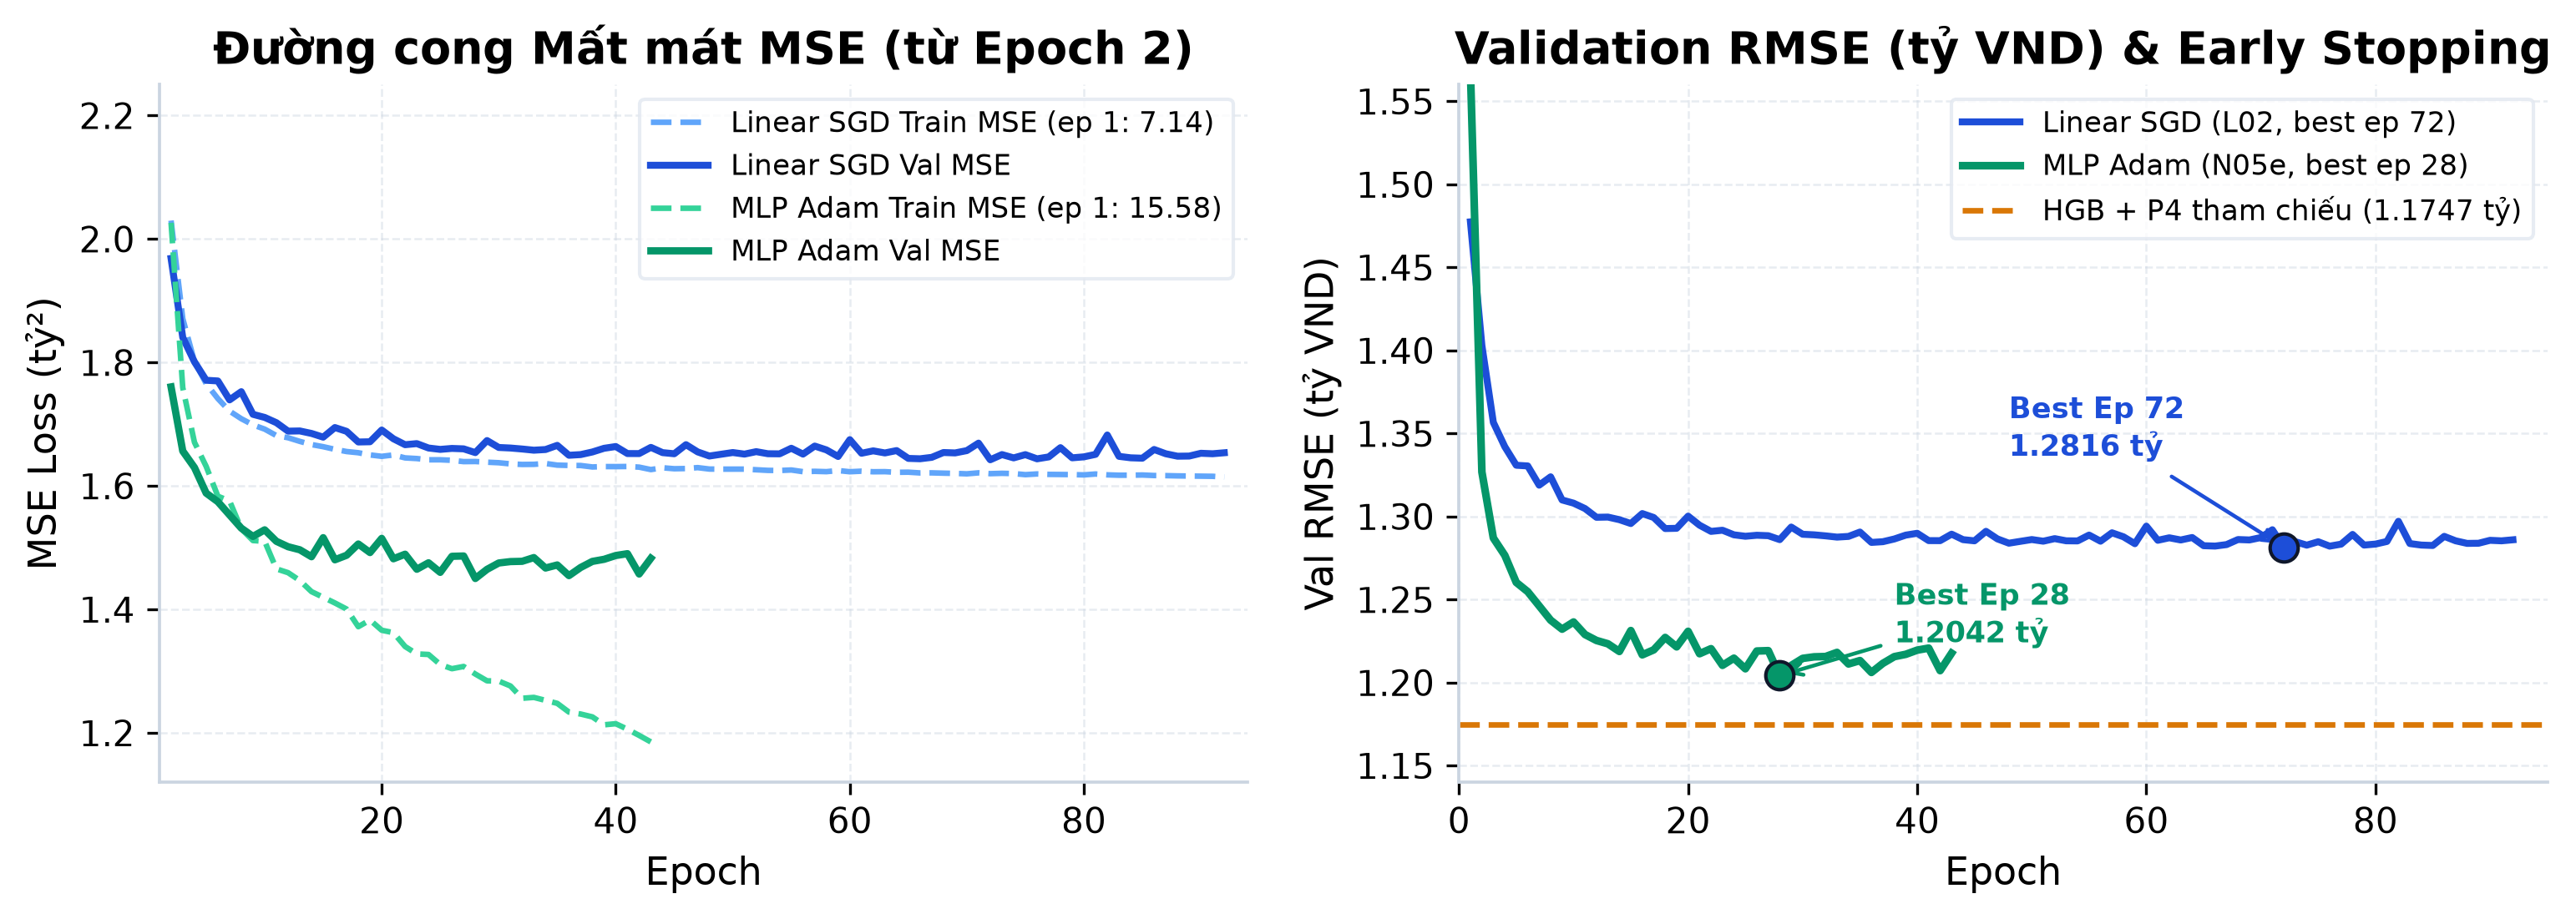

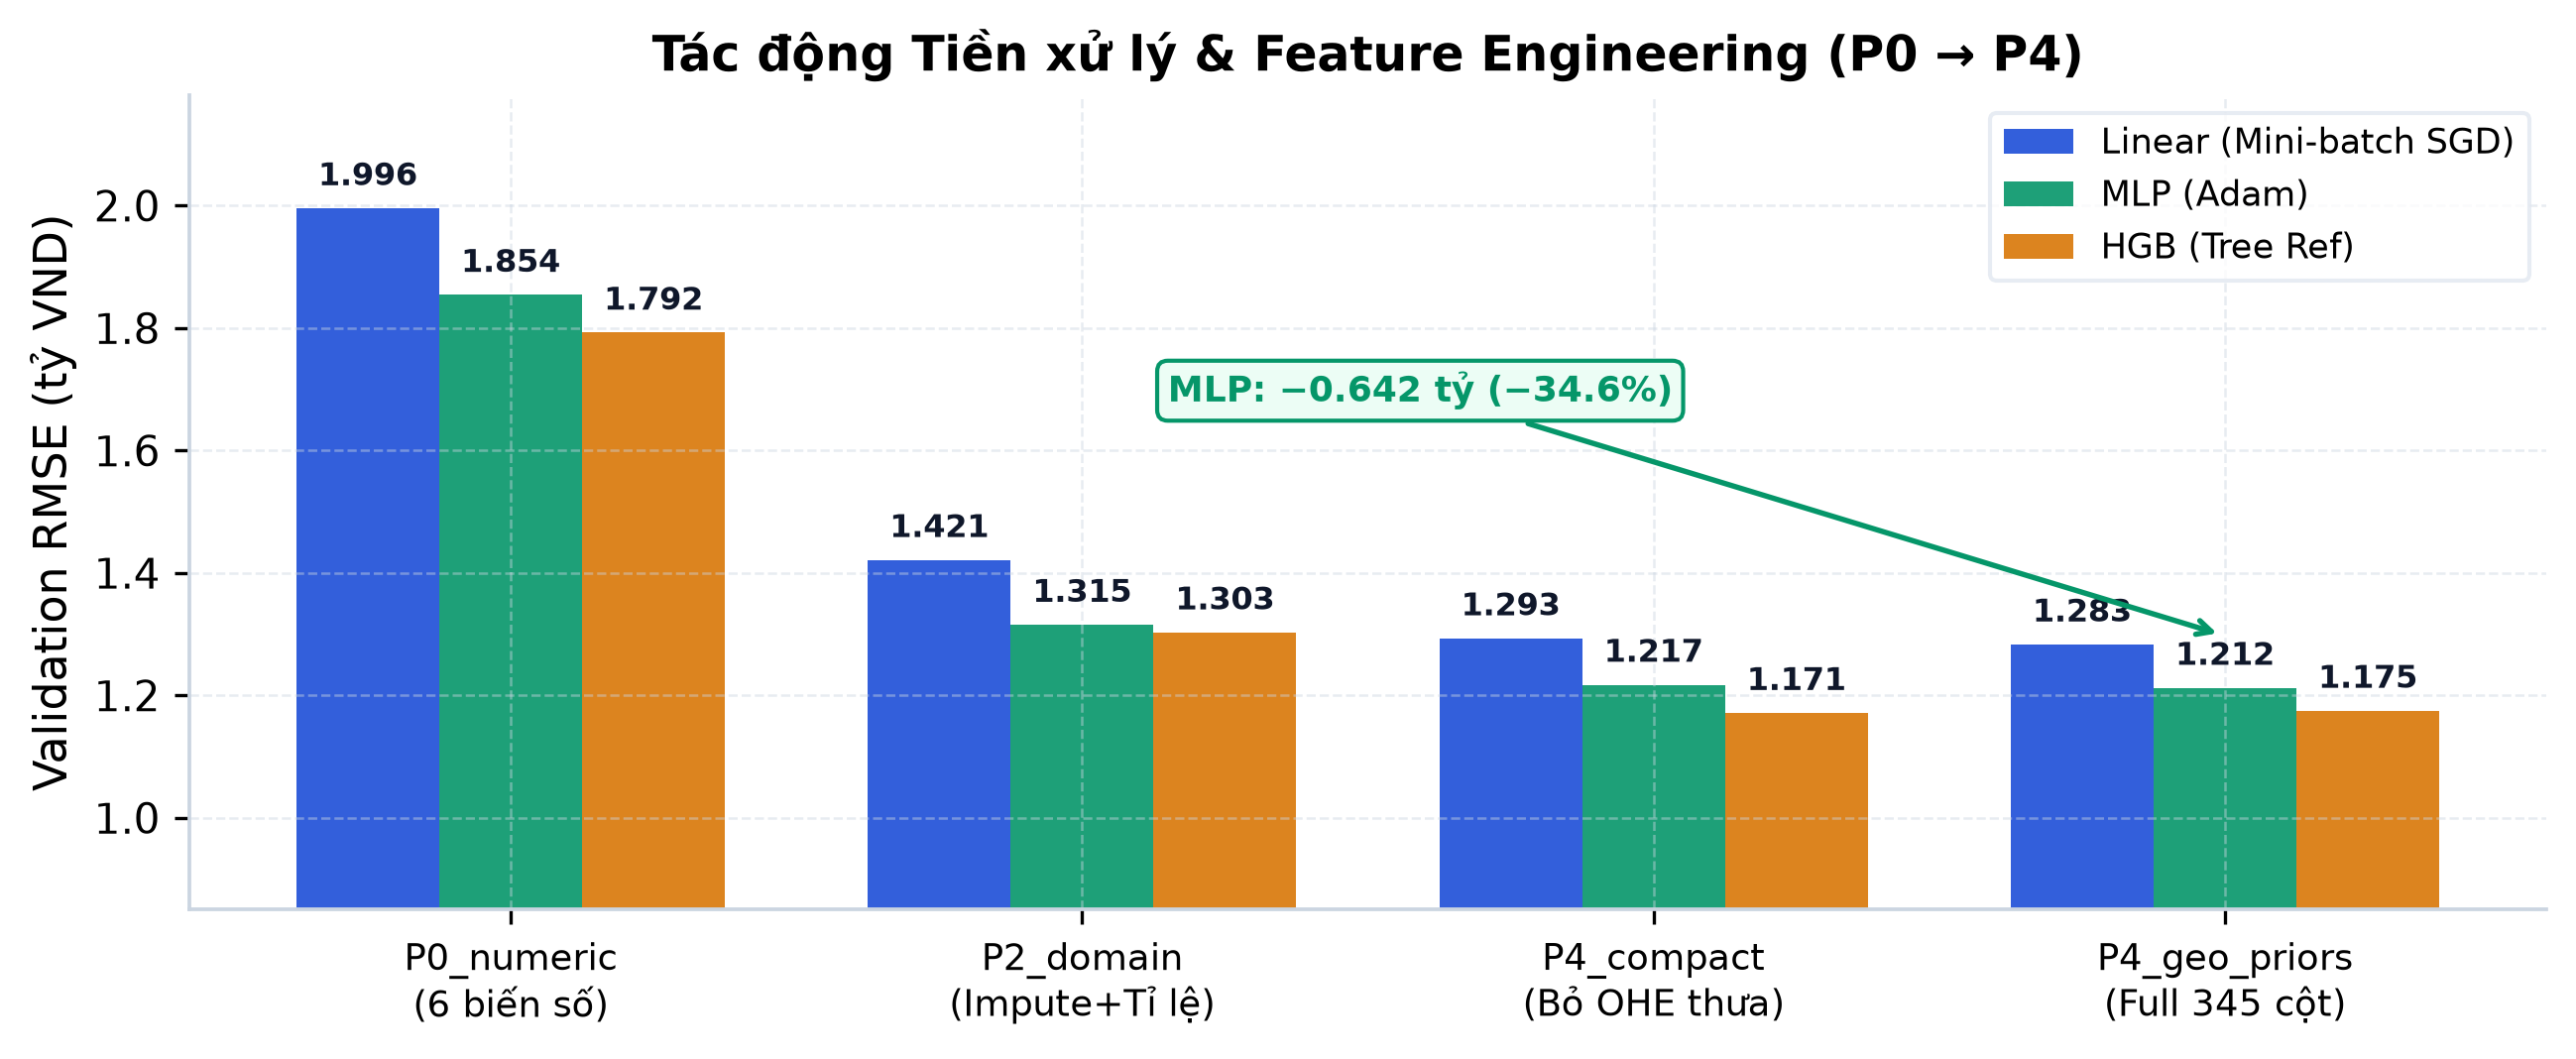

In [46]:
for fig_name in ("training_curves.png", "preprocessing_impact.png"):
    p = SLIDES_FIGURES_DIR / fig_name
    assert p.is_file(), f"Missing figure: {p}"
    display(Image(filename=str(p), width=820))

## Phần 4 — Đánh giá Cuối cùng trên Tập Test Độc lập & Phân tích Sai số (20%)

Sau khi khóa hoàn toàn kiến trúc và siêu tham số trên Validation:
- **Linear (`Mini-batch SGD`, `L02`):** `P4_geo_priors`, `batch_size=128`, `lr=0.01`, `epochs=72/92`.
- **MLP (`Backpropagation + Adam`, `N05e`):** `P4_geo_priors`, `hidden=(128,)`, `ReLU`, `Dropout=0.1`, `weight_decay=1e-4`, `batch_size=256`, `lr=0.001`, `epochs=28/43`.
- **Tham chiếu cây bên ngoài:** `HGB` & `Random Forest` (`P4_geo_priors`).

Tập kiểm thử **Test (`4,533` căn nhà)** chỉ được mở khóa **đúng một lần duy nhất**. Cell dưới đây tải dự đoán Test đã lưu tại [`artifacts/final_test_predictions.npz`](../artifacts/final_test_predictions.npz), tự tính lại toàn bộ chỉ số đánh giá bằng `evaluate_predictions()`, kiểm tra khớp tuyệt đối với kết quả đã log, phân tích sai số theo phân khúc giá/vùng miền và kiểm tra *Permutation Importance* trên tập Validation.

In [47]:
preds = np.load(ARTIFACTS_DIR / "final_test_predictions.npz")
y_test = np.asarray(preds["y_test"], dtype=float)
assert len(y_test) == len(te_idx) == 4533

print("=== 1. Final Locked Test Metrics (n = 4,533, recomputed directly via evaluate_predictions) ===")
print(f"  {'Model':14s} | {'RMSE':>7s} | {'MAE':>7s} | {'MedAE':>7s} | {'R2':>7s} | {'MAPE':>7s} | {'±10%':>7s} | {'±20%':>7s} | {'±1 tỷ':>7s}")
print("  " + "-" * 90)
for key, label in [
    ("linear_sgd", "Linear (SGD)"),
    ("mlp", "MLP (Adam)"),
    ("hgb", "HGB (Ref)"),
    ("rf", "RF (Ref)"),
]:
    y_pred = np.asarray(preds[f"test_pred_{key}"], dtype=float)
    m = evaluate_predictions(label, y_test, y_pred, export_to_slides=False)
    logged = summary["final_models"][key]["test"]
    for k in ("rmse", "mae", "medae", "r2", "mape", "within_10pct", "within_20pct", "within_1ty"):
        assert m[k] == logged[k], f"Mismatch for {key}.{k}: {m[k]} != {logged[k]}"
    print(
        f"  {label:14s} | {m['rmse']:7.4f} | {m['mae']:7.4f} | {m['medae']:7.4f} | {m['r2']:7.4f} | "
        f"{m['mape']:6.2f}% | {m['within_10pct']:7.4f} | {m['within_20pct']:7.4f} | {m['within_1ty']:7.4f}"
    )

print("\n=== 2. Test Error Breakdown by Price Band & Region — MLP (Adam, N05e) ===")
for row in summary["segment_reports"]["mlp"]:
    print(
        f"  {row['segment']:26s} n={row['count']:4d} | RMSE={row['rmse']:.4f} | "
        f"MAE={row['mae']:.4f} | MAPE={row['mape']:5.2f}% | ±20%={row['within_20pct']:.4f}"
    )

print("\n=== 3. Top 10 Validation Permutation Importance (MLP vs HGB) ===")
mlp_top = summary["val_permutation_importance"]["mlp"][:10]
hgb_top = summary["val_permutation_importance"]["hgb"][:10]
for rank in range(10):
    mi, hi = mlp_top[rank], hgb_top[rank]
    print(
        f"  #{rank+1:2d} | MLP: {mi['feature']:29s} (+{mi['delta_rmse_mean']:.4f}) | "
        f"HGB: {hi['feature']:24s} (+{hi['delta_rmse_mean']:.4f})"
    )

=== 1. Final Locked Test Metrics (n = 4,533, recomputed directly via evaluate_predictions) ===
  Model          |    RMSE |     MAE |   MedAE |      R2 |    MAPE |    ±10% |    ±20% |   ±1 tỷ
  ------------------------------------------------------------------------------------------
  Linear (SGD)   |  1.2936 |  0.9698 |  0.7558 |  0.6566 |  19.92% |  0.3920 |  0.6693 |  0.6267
  MLP (Adam)     |  1.2300 |  0.8987 |  0.6690 |  0.6896 |  17.72% |  0.4278 |  0.7106 |  0.6682
  HGB (Ref)      |  1.1955 |  0.8581 |  0.5994 |  0.7067 |  16.89% |  0.4604 |  0.7260 |  0.6878
  RF (Ref)       |  1.2026 |  0.8561 |  0.5966 |  0.7032 |  17.51% |  0.4789 |  0.7309 |  0.6925

=== 2. Test Error Breakdown by Price Band & Region — MLP (Adam, N05e) ===
  Giá thấp (< 4 tỷ)          n=1019 | RMSE=1.1715 | MAE=0.7952 | MAPE=30.67% | ±20%=0.5329
  Giá trung bình (4–7 tỷ)    n=2035 | RMSE=1.0234 | MAE=0.7894 | MAPE=14.68% | ±20%=0.7396
  Giá cao (≥ 7 tỷ)           n=1479 | RMSE=1.5000 | MAE=1.1205 | MAPE=

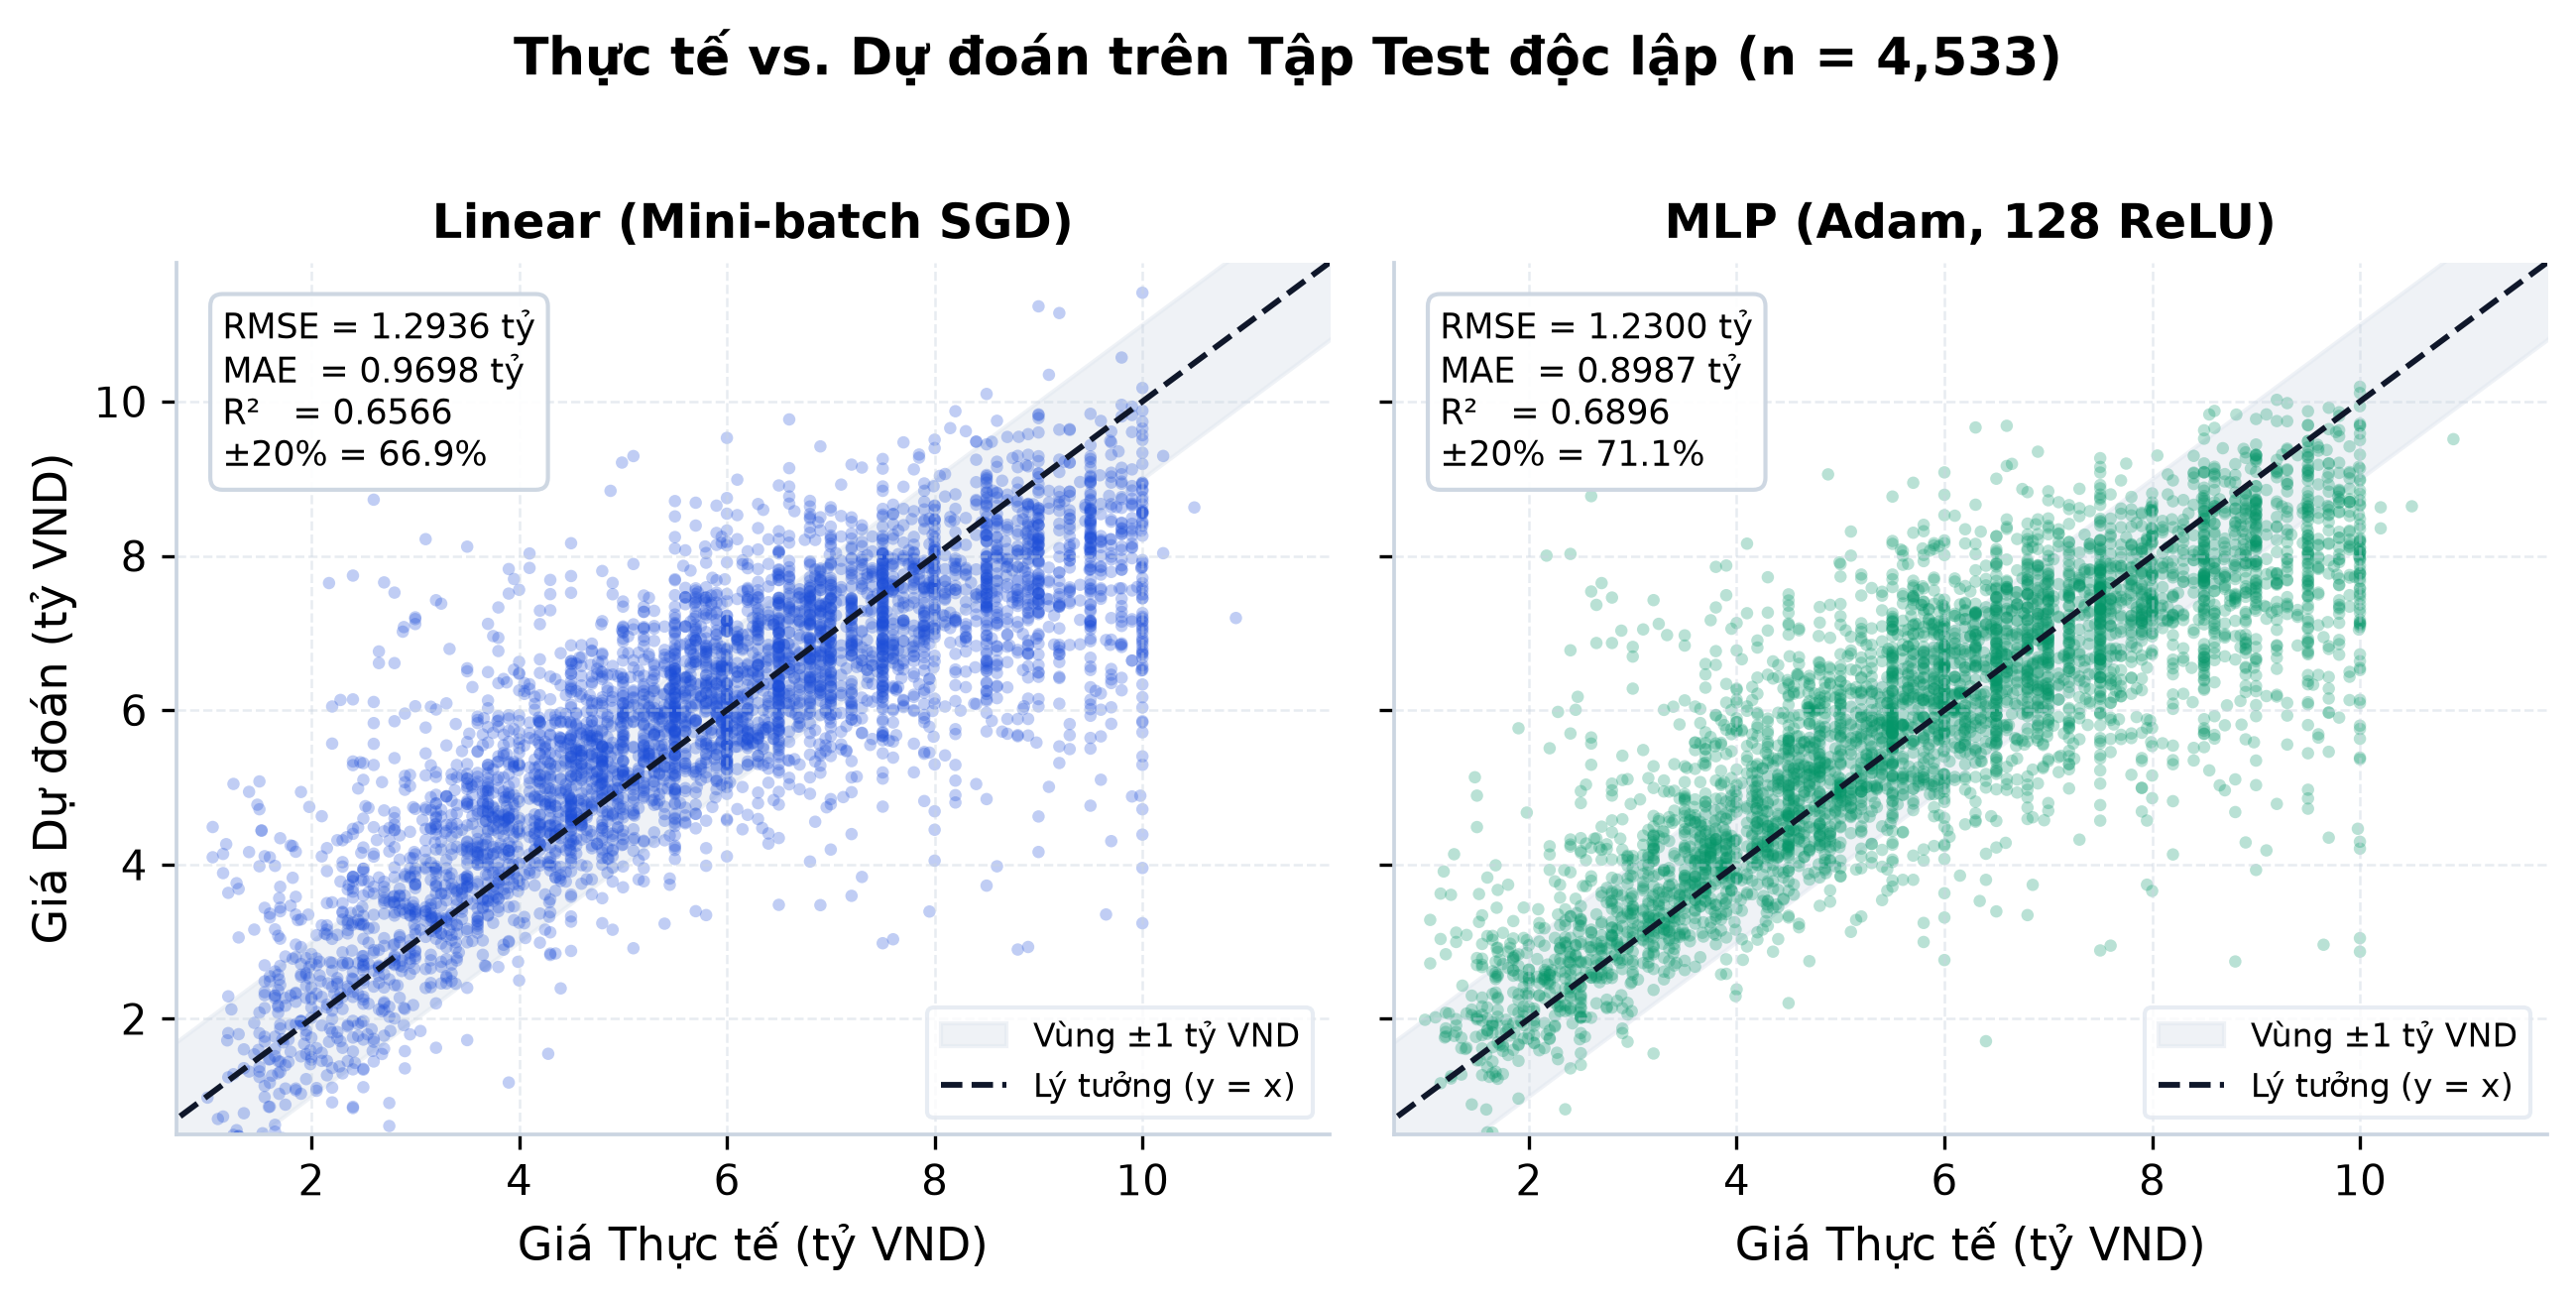

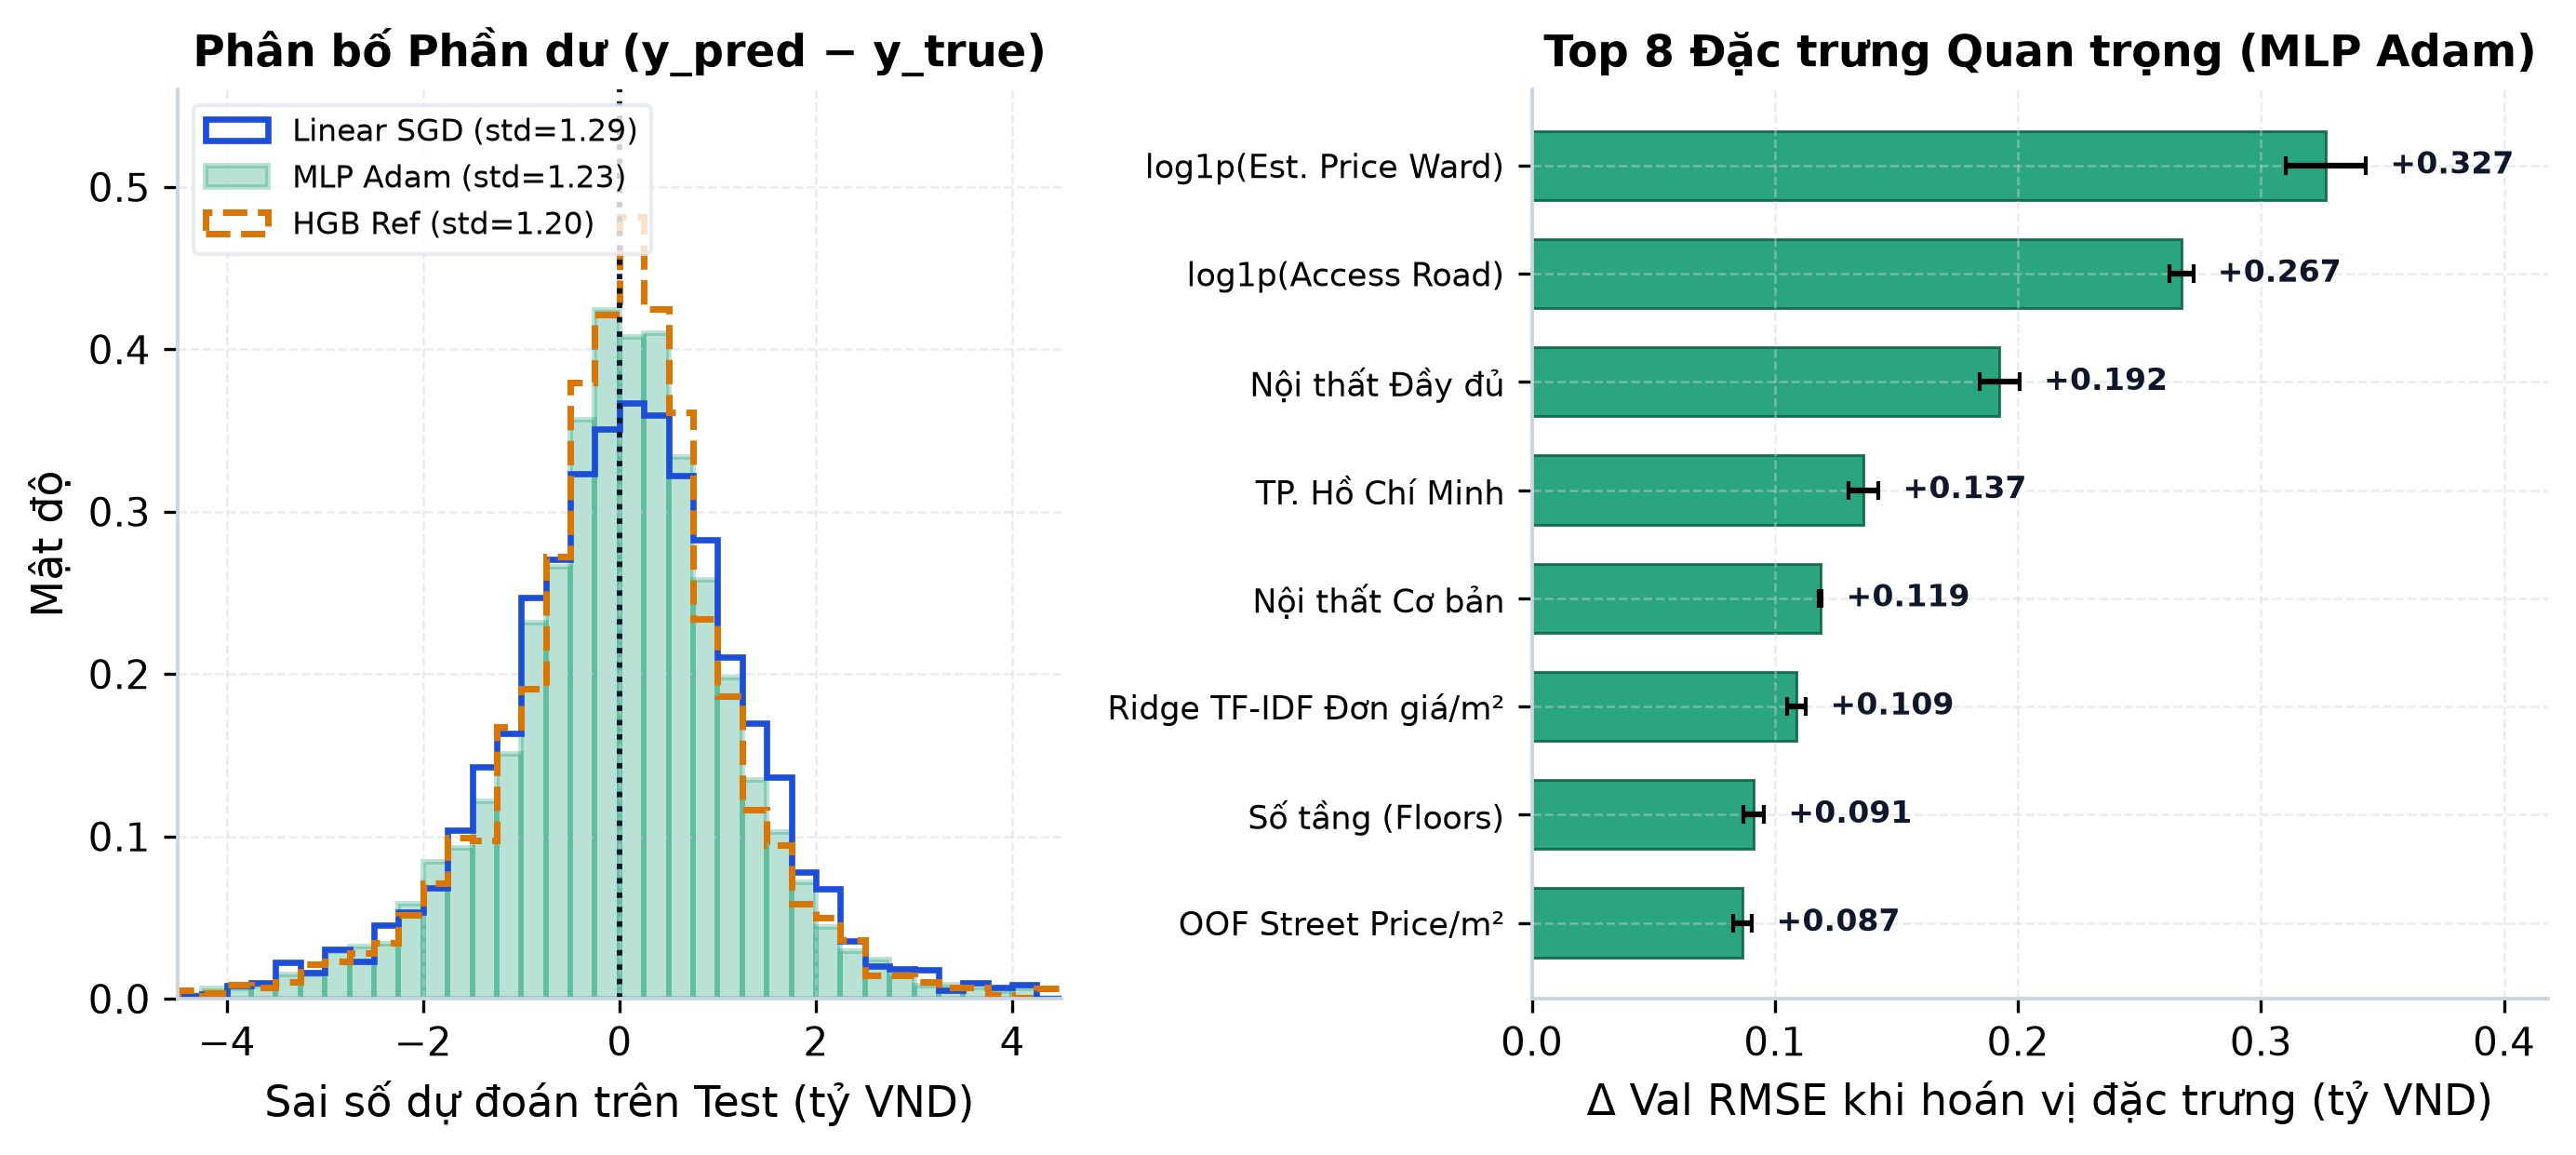

In [48]:
for fig_name in ("pred_vs_actual.png", "residual_analysis.png"):
    p = SLIDES_FIGURES_DIR / fig_name
    assert p.is_file(), f"Missing figure: {p}"
    display(Image(filename=str(p), width=820))

## Phần 5 — Tổng kết, Liên hệ Kiến thức Môn học & Hướng Phát triển (20%)

### 1. Tổng hợp Kết quả trên Tập Test Độc lập (`n = 4,533`)
- **Hướng 1 — Linear (`Mini-batch SGD`, `L02`):** `RMSE = 1.2936 tỷ`, `MAE = 0.9698 tỷ`, `R² = 0.6566`, `MAPE = 19.92%`, `66.9%` trong `±20%`.
- **Hướng 2 — MLP (`Backpropagation + Adam`, `N05e`):** `RMSE = 1.2300 tỷ`, `MAE = 0.8987 tỷ`, `R² = 0.6896`, `MAPE = 17.72%`, `71.1%` trong `±20%`, **vượt Linear SGD 0.0636 tỷ** và đạt độ ổn định đa seed trên Validation **`1.2079 ± 0.0032 tỷ`** (`seeds 42, 123, 2026`).
- **Mốc tham chiếu bên ngoài:** `HGB (RMSE = 1.1955 tỷ, R² = 0.7067)` & `Random Forest (RMSE = 1.2026 tỷ, R² = 0.7032)` — khoảng cách giữa `MLP` và `HGB` thu hẹp còn **`0.0345 tỷ`**.

### 2. Liên hệ Chặt chẽ với Kiến thức Môn học
1. **Bias – Variance Trade-off:** `Linear SGD` có khoảng cách Train–Val rất nhỏ nhưng chịu *high bias* (`Val RMSE 1.2816`). Việc thêm 1 tầng ẩn `128 ReLU` giảm mạnh bias (`1.2042`), trong khi tăng lên 2 tầng `(128, 64) ± BatchNorm` (`1.2232–1.2266`) làm tăng variance và sớm overfit ngay từ epoch 9–10.
2. **SGD vs. Adam & Vai trò Early Stopping:** `Adam` thích nghi bước học theo từng tham số giúp `MLP` đạt đáy Val RMSE chỉ sau **28 epochs** (`13.2s` trên Tesla T4), nhanh hơn nhiều so với `SGD` (`72 epochs`, `35.4s`). Kết hợp `Dropout(0.1) + weight_decay=1e-4` và dừng sớm giữ điểm tổng quát hóa tối ưu trước khi đường Val đi ngang.
3. **Sức mạnh của Feature Engineering (`P0 → P4`):** Áp dụng tri thức miền (`Giá ≈ Diện tích × Đơn giá khu vực` kết hợp OOF TF-IDF địa chỉ) giảm tới **0.642 tỷ RMSE (−34.6%)** trên MLP và **0.713 tỷ (−35.7%)** trên Linear SGD — lớn gấp nhiều lần mức cải thiện từ tinh chỉnh siêu tham số thuần túy.
4. **Kỷ luật Chống Data Leakage:** Khóa split theo `1,708` cụm tin lặp của môi giới (`StratifiedGroupKFold`), fit imputer/scaler riêng trên Train, dùng 5-fold OOF encoding và giữ tập Test đóng băng tới bước đánh giá cuối cùng.

### 3. Hạn chế & Hướng Phát triển Tiếp theo
- **Dữ liệu vi mô:** Sai số tuyệt đối vẫn lớn ở phân khúc `≥ 7 tỷ` (`RMSE 1.500 tỷ`) do thiếu tọa độ bản đồ chi tiết (`lat/lon`) và mô tả chất lượng nội thất/tiện ích hẻm từ tin rao bán; có thể tích hợp mô hình ngôn ngữ tiếng Việt (PhoBERT) và ước lượng khoảng tin cậy giá (*Conformal Prediction*).